# FarmTech Neural Vision

**Arquivo:** EdemirSufiatti_rm571375_pbl_fase6.ipynb

**Grupo**

- Edemir Sufiatti — RM571375
- Carlos Magnus Costa Amaral — RM573978
- Georgia Mendes Rocha — RM573281
- Marina Leme Soares — RM570461

## Objetivo

Localizar banana e milho em fotografia de campo. O modelo é o YOLOv5: uma rede de detecção que devolve a classe e a caixa em volta do objeto.

- **banana** — classe 0
- **milho** — classe 1

O treino parte de `yolov5s.pt`, pesos já ajustados em um conjunto genérico, e especializa essa rede nas duas classes. Imagem, pesos iniciais e pastas ficam iguais nas duas simulações. Só muda o número de épocas: **30** e **60**.

A execução usa Google Colab com GPU **T4**. As fotos estão em `Meu Drive/FarmTech_Neural_Vision/dataset`, da conta **edefiapia@gmail.com**:

https://drive.google.com/drive/folders/18FQL7_woTacQxS92qzcNKTtFyj0Mj8NZ?usp=drive_link


## 1. Dataset

Cada classe tem 40 imagens, distribuídas entre treino, validação e teste sem repetição entre os conjuntos. Essa separação evita vazamento de dados (data leakage) e reduz o risco de métricas artificialmente otimistas.

| Conjunto | Imagens por classe | Função |
| --- | --- | --- |
| Treino | 32 | Ajustar os pesos do modelo |
| Validação | 4 | Avaliar o modelo em imagens não usadas para ajustar os pesos |
| Teste | 4 | Avaliar qualitativamente o `best.pt` em imagens separadas do treino e da validação |

As bounding boxes foram marcadas manualmente no [MakeSense.ai](https://www.makesense.ai/), na tarefa Object Detection, e exportadas no formato YOLO. Cada linha representa um objeto:

```text
class_id x_center y_center width height
```

Os IDs são banana = 0 e milho = 1. As coordenadas do centro e as dimensões da caixa são normalizadas entre 0 e 1. O arquivo `.txt` possui o mesmo nome-base (stem) da imagem.

```text
FarmTech_Neural_Vision/dataset/
├── train/images/banana e milho    train/labels/banana e milho
├── val/images/banana e milho      val/labels/banana e milho
└── test/images/banana e milho     test/labels/banana e milho
```


## 2. Sequência

1. Montar o Drive e conferir 32/4/4 fotos e rótulos por classe.
2. Clonar o YOLOv5 e instalar as dependências.
3. Gravar o `data.yaml` com as pastas e os nomes das classes.
4. Treinar 30 épocas e, em seguida, 60.
5. Ler a linha `all` de cada treino e guardar `runs/train` no Drive.
6. Rodar o `detect.py` nas 8 fotos de teste e guardar `runs/detect` no Drive.

Execute uma célula de cada vez. Se a sessão cair, recomece pela montagem do Drive. Se o instalador pedir uma opção de biblioteca, escolha **3**.


## 3. Montar o Drive

O dataset oficial do grupo está armazenado no Google Drive. A pasta pública é:

https://drive.google.com/drive/folders/18FQL7_woTacQxS92qzcNKTtFyj0Mj8NZ?usp=drive_link

`drive.mount('/content/drive')` monta o Drive da conta autorizada naquela sessão. O código espera o projeto em `/content/drive/MyDrive/FarmTech_Neural_Vision/`. Ao usar outra conta, essa pasta precisa estar disponível no MyDrive da sessão; o acesso público ao link não faz a pasta aparecer automaticamente nesse caminho.

A célula verifica a existência do dataset antes de contar arquivos, confere 32 imagens de treino, 4 de validação e 4 de teste por classe e verifica a correspondência entre imagem e label pelo mesmo stem. Se houver problema, interrompe a execução com uma mensagem explicativa. Não há download automático.


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path

link = "https://drive.google.com/drive/folders/18FQL7_woTacQxS92qzcNKTtFyj0Mj8NZ?usp=drive_link"
print("Pasta no Drive:", link)

RAIZ_DRIVE = Path('/content/drive/MyDrive/FarmTech_Neural_Vision')
DATASET = RAIZ_DRIVE / 'dataset'
if not DATASET.is_dir():
    raise FileNotFoundError(f'Dataset não encontrado em {DATASET}. Disponibilize a pasta FarmTech_Neural_Vision no MyDrive da conta autorizada nesta sessão. Pasta pública: {link}')
esperado = {"train": 32, "val": 4, "test": 4}
erros = []

for conjunto, n in esperado.items():
    for classe in ("banana", "milho"):
        imagens = list((DATASET / conjunto / "images" / classe).glob("*.jpg"))
        rotulos = list((DATASET / conjunto / "labels" / classe).glob("*.txt"))
        print(conjunto, classe, "imagens:", len(imagens), "rotulos:", len(rotulos))
        if len(imagens) != n or len(rotulos) != n or {p.stem for p in imagens} != {p.stem for p in rotulos}:
            erros.append(conjunto + "/" + classe + " imagens " + str(len(imagens)) + " rotulos " + str(len(rotulos)))

if erros:
    raise RuntimeError("Dataset no Drive incompleto em treino, validação ou teste: " + " | ".join(erros))
print("Dataset conferido: treino, validação e teste possuem as quantidades esperadas para banana e milho.")


Mounted at /content/drive
Pasta no Drive: https://drive.google.com/drive/folders/18FQL7_woTacQxS92qzcNKTtFyj0Mj8NZ?usp=drive_link
train banana imagens: 32 rotulos: 32
train milho imagens: 32 rotulos: 32
val banana imagens: 4 rotulos: 4
val milho imagens: 4 rotulos: 4
test banana imagens: 4 rotulos: 4
test milho imagens: 4 rotulos: 4
Dataset conferido: treino, validação e teste possuem as quantidades esperadas para banana e milho.


## 4. YOLOv5

O projeto utiliza transfer learning/fine-tuning a partir de `yolov5s.pt`, pré-treinado, em vez de treinar integralmente o YOLO do zero. São mantidos os scripts oficiais: `train.py` ajusta os pesos e `detect.py` realiza as detecções nas imagens de teste.

O treinamento original registrou `YOLOv5 v7.0-555-g4add2aff`. A célula clona o repositório oficial se necessário, fixa a revisão `4add2aff` antes de instalar os requirements e exibe o commit efetivamente utilizado. Se já estiver nessa revisão, não repete o checkout. A integração interativa do Weights & Biases é desabilitada antes dos treinamentos.


In [ ]:
import os
import subprocess
from pathlib import Path

YOLO_DIR = Path('/content/yolov5')
REVISAO_YOLO = '4add2aff'

# Evita prompts interativos do Weights & Biases nos treinamentos.
os.environ['WANDB_MODE'] = 'disabled'

if not YOLO_DIR.exists():
    subprocess.run(['git', 'clone', 'https://github.com/ultralytics/yolov5.git', str(YOLO_DIR)], check=True)

def git_yolo(*argumentos):
    return subprocess.check_output(['git', '-C', str(YOLO_DIR), *argumentos], text=True).strip()

revisao_esperada = git_yolo('rev-parse', REVISAO_YOLO + '^{commit}')
if git_yolo('rev-parse', 'HEAD') != revisao_esperada:
    subprocess.run(['git', '-C', str(YOLO_DIR), 'checkout', '--detach', revisao_esperada], check=True)

print('Commit YOLOv5 utilizado:', git_yolo('rev-parse', '--short', 'HEAD'))
!pip install -r /content/yolov5/requirements.txt

print('Arquivo de treino:', (YOLO_DIR / 'train.py').is_file())
print('Arquivo de teste:', (YOLO_DIR / 'detect.py').is_file())


Commit YOLOv5 utilizado: 4add2aff
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 3.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 43.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.1/96.1 kB 10.7 MB/s eta 0:00:00
Arquivo de treino: True
Arquivo de teste: True


## 5. GPU

Os experimentos originais foram executados em GPU NVIDIA Tesla T4. No Colab, selecione **Alterar o tipo de ambiente de execução**, **GPUs: T4** e **Salvar**.

A comparação de tempo só é diretamente válida quando o hardware é mantido. Para reproduzir os tempos apresentados, use T4 ou ambiente equivalente, sem esperar tempos exatamente iguais em outra GPU. Embora o treinamento possa usar CPU, este notebook exige CUDA para executar os experimentos no ambiente de GPU previsto.


In [ ]:
import torch

print('GPU disponível:', torch.cuda.is_available())
if not torch.cuda.is_available():
    raise RuntimeError('CUDA não está disponível. No Colab, selecione GPU T4 em Alterar o tipo de ambiente de execução e execute novamente as células de preparação.')
print('Nome da GPU:', torch.cuda.get_device_name(0))


GPU disponível: True
Nome da GPU: Tesla T4


## 6. data.yaml

O `data.yaml` informa os caminhos e as classes ao YOLOv5; o arquivo em si não realiza treinamento. A célula gera caminhos absolutos a partir de `DATASET` e grava `dataset/data.yaml`.

```yaml
train: /content/drive/MyDrive/FarmTech_Neural_Vision/dataset/train/images
val: /content/drive/MyDrive/FarmTech_Neural_Vision/dataset/val/images
test: /content/drive/MyDrive/FarmTech_Neural_Vision/dataset/test/images
nc: 2
names:
  0: "banana"
  1: "milho"
```

`train` aponta para treino; `val`, para validação; `test` registra o conjunto reservado para teste. `nc` informa explicitamente duas classes e `names` relaciona os IDs aos nomes. O YOLOv5 localiza os rótulos substituindo o componente `images` por `labels` no caminho.


In [ ]:
caminho = DATASET / 'data.yaml'
DATA_YAML = str(caminho)

texto = f'''train: {DATASET / 'train' / 'images'}
val: {DATASET / 'val' / 'images'}
test: {DATASET / 'test' / 'images'}
nc: 2
names:
  0: "banana"
  1: "milho"
'''

caminho.write_text(texto, encoding='utf-8')
print(caminho.read_text(encoding='utf-8'))


train: /content/drive/MyDrive/FarmTech_Neural_Vision/dataset/train/images
val: /content/drive/MyDrive/FarmTech_Neural_Vision/dataset/val/images
test: /content/drive/MyDrive/FarmTech_Neural_Vision/dataset/test/images
nc: 2
names:
  0: "banana"
  1: "milho"



## 7. Simulação 1 — 30 épocas

Uma época corresponde a um ciclo completo sobre as 64 imagens de treino, 32 por classe. Ambas as simulações usam o mesmo dataset, peso inicial `yolov5s.pt`, tamanho de imagem 640 e os mesmos demais parâmetros definidos no notebook. As diferenças planejadas são o número de épocas e o nome da pasta de saída.

- `--weights yolov5s.pt` — pesos iniciais pré-treinados.
- `--img 640` — tamanho de imagem utilizado no treinamento.
- `--epochs 30` — quantidade de ciclos de treinamento.
- `--name exp30` — pasta desta simulação.
- `--seed 0` — seed fixo, suportado pela revisão utilizada e igual ao padrão do script; não garante determinismo absoluto.

Ao terminar, o `train.py` avalia o `best.pt` no conjunto de validação e imprime Precision, Recall, mAP50 e mAP50-95. A linha `all` resume as métricas das duas classes. O tempo total é medido na célula.


In [ ]:
import time

inicio = time.time()
# Mesmo dataset, pesos iniciais, imagem 640 e demais parâmetros; saída exp30.
# Seed 0 é o padrão desta revisão; --exist-ok permite reutilizar a pasta de saída.
!python /content/yolov5/train.py --data "{DATA_YAML}" --weights yolov5s.pt --img 640 --epochs 30 --name exp30 --seed 0 --exist-ok
print('Tempo da simulação de 30 épocas: {:.0f} s'.format(time.time() - inicio))

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
WARNING ⚠️ wandb: wandb is deprecated and will be removed in a future release. See supported integrations at https://github.com/ultralytics/yolov5#integrations.
I0000 00:00:1791377837.207112    1033 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
train: weights=yolov5s.pt, cfg=, data=/content/drive/MyDrive/FarmTech_Neural_Vision/dataset/data.yaml, hyp=yolov5/data/hyps/hyp.scratch-low.yaml, epochs=30, batch_size=16, imgsz=640, rect=False, resume=False, nosave=False, noval=False, noautoanchor=False, noplots=False, evolve=None, evolve_population=yolov5/data/hyps, resume_evolve=None, bucket=, cache=None, image_weights=False, device=, multi_scale=False, single_cls=F

## 8. Simulação 2 — 60 épocas

Esta simulação mantém o mesmo dataset, peso inicial `yolov5s.pt`, tamanho de imagem 640, seed 0 e demais parâmetros da execução de 30 épocas. As diferenças planejadas são `--epochs 60` e a pasta de saída `exp60`.

A execução de 60 épocas realiza o dobro de ciclos completos sobre o conjunto de treinamento em relação à de 30 épocas, considerando o mesmo dataset. Isso não garante melhora na validação ou no teste. A comparação usa as métricas de validação do `best.pt`, o tempo medido e a avaliação qualitativa das imagens de teste.


Os valores apresentados nesta análise correspondem à execução registrada neste notebook. Foi utilizada `seed=0` para aumentar a reprodutibilidade do experimento. Ainda assim, treinamentos de redes neurais em GPU podem apresentar pequenas variações entre execuções devido a operações estocásticas e não determinísticas. Portanto, uma nova execução pode produzir métricas ligeiramente diferentes; por isso, a comparação deve ser interpretada considerando a configuração experimental mantida e a variabilidade inerente ao treinamento. As conclusões se referem a esta execução e não constituem uma regra geral sobre o efeito do número de épocas.

In [ ]:
import time

inicio = time.time()
# Mesmo dataset, pesos iniciais, imagem 640 e demais parâmetros; saída exp60.
# Seed 0 é o padrão desta revisão; --exist-ok permite reutilizar a pasta de saída.
!python /content/yolov5/train.py --data "{DATA_YAML}" --weights yolov5s.pt --img 640 --epochs 60 --name exp60 --seed 0 --exist-ok
print('Tempo da simulação de 60 épocas: {:.0f} s'.format(time.time() - inicio))

WARNING ⚠️ wandb: wandb is deprecated and will be removed in a future release. See supported integrations at https://github.com/ultralytics/yolov5#integrations.
I0000 00:00:1791378621.131522    4598 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
train: weights=yolov5s.pt, cfg=, data=/content/drive/MyDrive/FarmTech_Neural_Vision/dataset/data.yaml, hyp=yolov5/data/hyps/hyp.scratch-low.yaml, epochs=60, batch_size=16, imgsz=640, rect=False, resume=False, nosave=False, noval=False, noautoanchor=False, noplots=False, evolve=None, evolve_population=yolov5/data/hyps, resume_evolve=None, bucket=, cache=None, image_weights=False, device=, multi_scale=False, single_cls=False, optimizer=SGD, sync_bn=False, workers=8, project=yolov5/runs/train, name=exp60, exist_ok=True, quad=False, cos_lr=False, label_smoothing=0.0, patience=100, freeze=[0], save_period=-1, seed=0, local_rank=-1, entity=None, upload_dataset=False, bbox_interval=-1
github: ⚠️ YOLOv5 is out of 

## 9. Leitura da validação

A linha `all` resume a validação global; as linhas por classe detalham banana e milho. Os resultados comparados correspondem à avaliação do `best.pt`.

- **Precision (P):** entre as detecções realizadas pelo modelo, indica a proporção das que correspondem corretamente aos objetos reais.
- **Recall (R):** entre os objetos reais anotados, indica a proporção dos que o modelo conseguiu detectar.
- **IoU:** medida de sobreposição entre a bounding box prevista pelo modelo e a de referência, calculada como a área de interseção dividida pela área de união das caixas.
- **mAP50:** Mean Average Precision calculada utilizando limiar de IoU igual a 0,50. Resume a Average Precision das classes, considerando a relação entre Precision e Recall ao variar o limiar de confiança.
- **mAP50-95:** média da Average Precision calculada em múltiplos limiares de IoU, de 0,50 a 0,95, em passos de 0,05. É mais rigorosa porque avalia a qualidade da detecção em diferentes exigências de sobreposição.

O `best.pt` corresponde ao checkpoint selecionado pelo processo de validação do YOLOv5, segundo seu critério de seleção; não é simplesmente a época com maior mAP50. As curvas de loss e de mAP ficam em `results.png`, na pasta de cada simulação.


Curvas de exp30


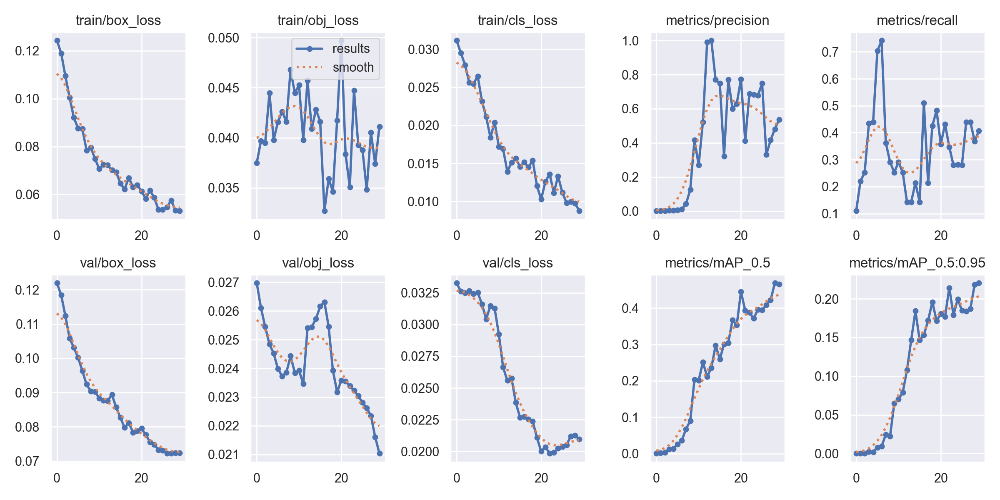

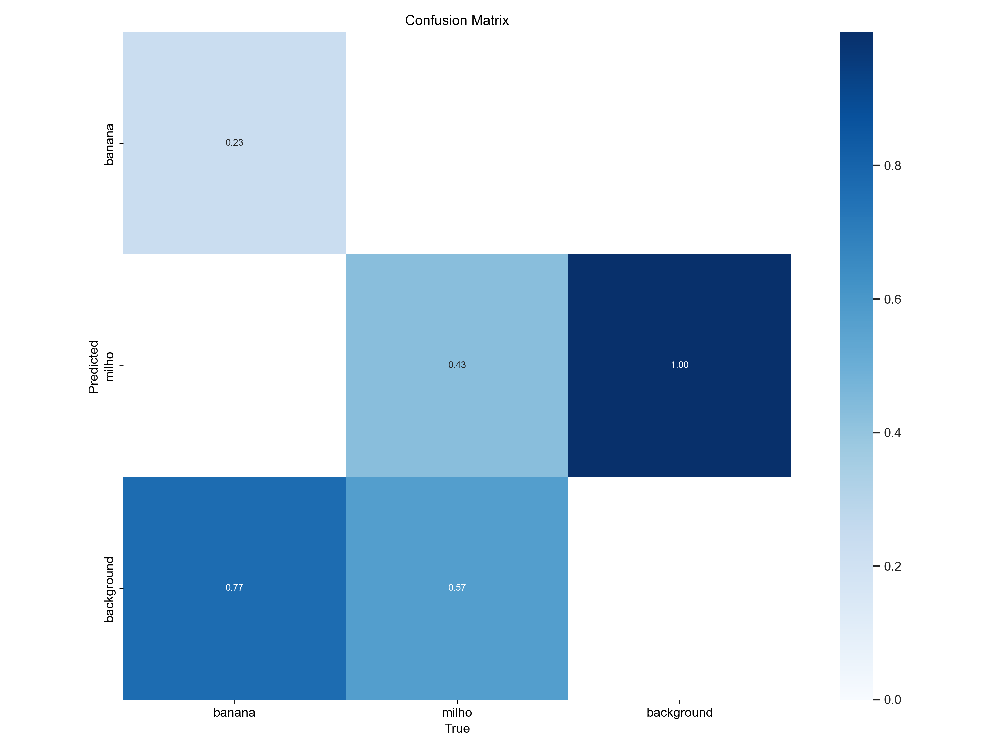

Curvas de exp60


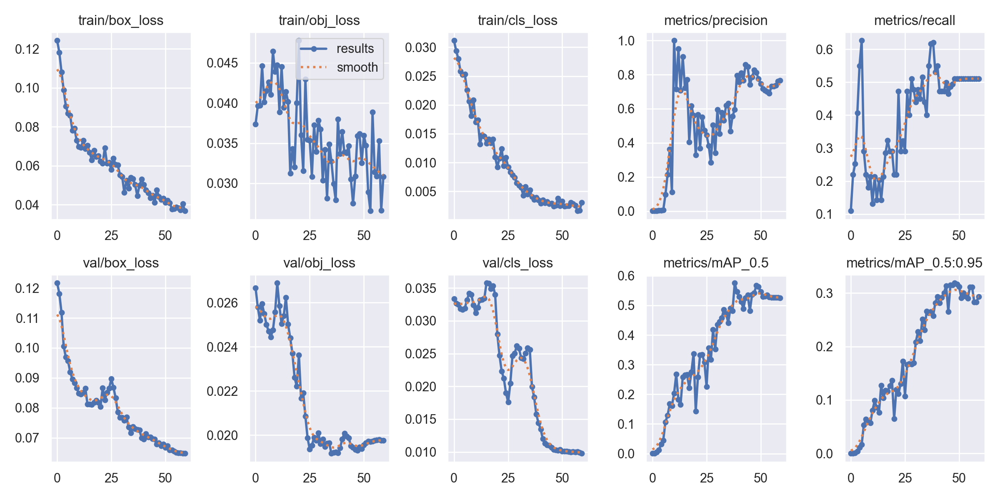

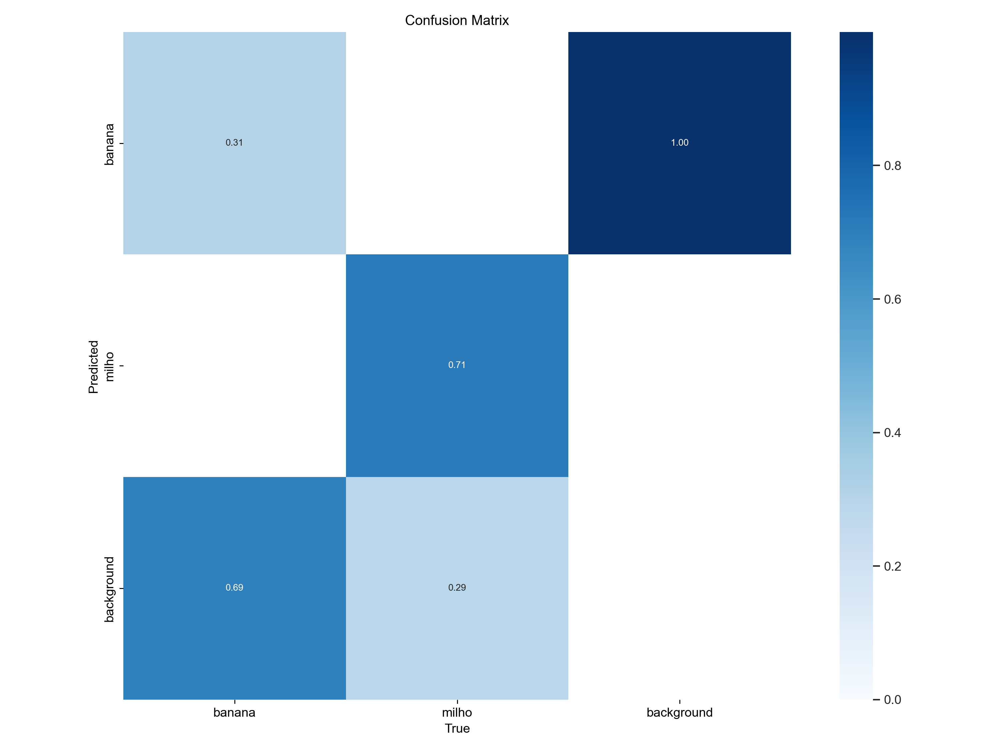

In [ ]:
from pathlib import Path
from IPython.display import Image, display

for nome in ('exp30', 'exp60'):
    pasta = Path('/content/yolov5/runs/train') / nome
    print('Curvas de', nome)
    for figura in ('results.png', 'confusion_matrix.png'):
        caminho = pasta / figura
        if caminho.is_file():
            display(Image(filename=str(caminho), width=640))
        else:
            print('Ainda não existe:', caminho)

## 10. Gravar o treino no Drive

O disco do Colab some ao fim da sessão. Antes do teste, esta célula copia `runs/train/exp30` e `runs/train/exp60` para a pasta principal do Drive, ao lado de `dataset`:

`Meu Drive/FarmTech_Neural_Vision/runs`

https://drive.google.com/drive/folders/18FQL7_woTacQxS92qzcNKTtFyj0Mj8NZ?usp=drive_link

Cada pasta traz o `best.pt` e as curvas. A cópia reutiliza `RAIZ_DRIVE`, no Drive da conta autorizada anteriormente. As fotos do teste entram em `runs/detect` na seção 11.


In [ ]:
import shutil
from pathlib import Path

origem_tipo = Path('/content/yolov5/runs/train')
destino = RAIZ_DRIVE / 'runs' / 'train'

if not origem_tipo.is_dir():
    raise RuntimeError(f'Nenhum resultado de treino encontrado em {origem_tipo}. Execute os treinamentos antes desta célula.')

pastas_treino = sorted(p for p in origem_tipo.iterdir() if p.is_dir())
if not pastas_treino:
    raise RuntimeError(f'Nenhuma pasta de resultado de treino encontrada em {origem_tipo}. Execute os treinamentos antes desta célula.')

destino.mkdir(parents=True, exist_ok=True)
print('Pasta principal:', RAIZ_DRIVE)
print('Resultados de treino em:', destino)

for origem in pastas_treino:
    alvo = destino / origem.name
    # Confere o destino antes de substituir uma pasta de resultado existente.
    if not alvo.resolve().is_relative_to(destino.resolve()):
        raise RuntimeError(f'Destino fora da pasta de treinamento esperada: {alvo}')
    if alvo.exists():
        shutil.rmtree(alvo)
    shutil.copytree(origem, alvo)
    print('gravado:', alvo)

print('Conferência dos resultados de treino no Drive:')
for arquivo in sorted(destino.rglob('*')):
    if arquivo.is_file() and (arquivo.name in ('best.pt', 'results.png') or arquivo.suffix == '.jpg'):
        print(' ', arquivo.relative_to(RAIZ_DRIVE), arquivo.stat().st_size)


Pasta principal: /content/drive/MyDrive/FarmTech_Neural_Vision
Resultados de treino em: /content/drive/MyDrive/FarmTech_Neural_Vision/runs/train
gravado: /content/drive/MyDrive/FarmTech_Neural_Vision/runs/train/exp30
gravado: /content/drive/MyDrive/FarmTech_Neural_Vision/runs/train/exp60
Conferência dos resultados de treino no Drive:
  runs/train/exp30/labels.jpg 185037
  runs/train/exp30/labels_correlogram.jpg 192668
  runs/train/exp30/results.png 346547
  runs/train/exp30/train_batch0.jpg 547662
  runs/train/exp30/train_batch1.jpg 498343
  runs/train/exp30/train_batch2.jpg 582776
  runs/train/exp30/val_batch0_labels.jpg 387796
  runs/train/exp30/val_batch0_pred.jpg 362964
  runs/train/exp30/weights/best.pt 14448047
  runs/train/exp60/labels.jpg 185037
  runs/train/exp60/labels_correlogram.jpg 192668
  runs/train/exp60/results.png 358058
  runs/train/exp60/train_batch0.jpg 561289
  runs/train/exp60/train_batch1.jpg 509290
  runs/train/exp60/train_batch2.jpg 582776
  runs/train/exp60/v

## 11. Teste

O teste não altera os pesos nem escolhe o `best.pt`. São 8 imagens reservadas, 4 de banana e 4 de milho, separadas do treino e da validação.

O script oficial `detect.py` usa o `best.pt` de cada simulação, `exp30` e `exp60`, e grava as imagens com as caixas. O comando define explicitamente `--conf-thres 0.25`, valor padrão confirmado na revisão `4add2aff`, para tornar rastreável o limiar de confiança sem alterar o comportamento padrão.

Como as imagens estão em subpastas `test/images/banana` e `test/images/milho`, a célula reúne temporariamente as 8 imagens em `/content/teste_fotos` para usar uma única pasta de origem. Em seguida, copia os resultados para `FarmTech_Neural_Vision/runs/detect` no Drive. A avaliação é qualitativa e envolve objetos detectados, localização e qualidade das bounding boxes.


In [ ]:
from pathlib import Path
import shutil

origem = DATASET / 'test' / 'images'
destino = Path('/content/teste_fotos')
if destino.exists():
    shutil.rmtree(destino)
destino.mkdir()

for foto in origem.rglob('*.jpg'):
    shutil.copy2(foto, destino / foto.name)

print('Fotos de teste:', len(list(destino.glob('*.jpg'))))

!python /content/yolov5/detect.py --weights /content/yolov5/runs/train/exp30/weights/best.pt --img 640 --conf-thres 0.25 --source /content/teste_fotos --name exp30 --exist-ok
!python /content/yolov5/detect.py --weights /content/yolov5/runs/train/exp60/weights/best.pt --img 640 --conf-thres 0.25 --source /content/teste_fotos --name exp60 --exist-ok

raiz = RAIZ_DRIVE
destino = raiz / 'runs' / 'detect'
origem_tipo = Path('/content/yolov5/runs/detect')
if origem_tipo.is_dir():
    for origem in sorted(p for p in origem_tipo.iterdir() if p.is_dir()):
        alvo = destino / origem.name
        if alvo.exists():
            shutil.rmtree(alvo)
        shutil.copytree(origem, alvo)
        print('gravado:', alvo)
else:
    print('O teste não gerou pasta para gravar no Drive.')


Fotos de teste: 8
detect: weights=['/content/yolov5/runs/train/exp30/weights/best.pt'], source=/content/teste_fotos, data=yolov5/data/coco128.yaml, imgsz=[640, 640], conf_thres=0.25, iou_thres=0.45, max_det=1000, device=, view_img=False, save_txt=False, save_format=0, save_csv=False, save_conf=False, save_crop=False, nosave=False, classes=None, agnostic_nms=False, augment=False, update=False, project=yolov5/runs/detect, name=exp30, exist_ok=True, line_thickness=3, hide_labels=False, hide_conf=False, half=False, dnn=False, vid_stride=1
YOLOv5 🚀 v7.0-555-g4add2aff Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)

Fusing layers... 
Model summary: 68 layers, 7,015,519 parameters, 0 gradients, 15.8 GFLOPs
image 1/8 /content/teste_fotos/banana_01.jpg: 640x480 (no detections), 27.5ms
image 2/8 /content/teste_fotos/banana_02.jpg: 480x640 (no detections), 28.5ms
image 3/8 /content/teste_fotos/banana_03.jpg: 480x640 1 banana, 12.3ms
image 4/8 /content/teste_fotos/banana_04.jpg: 384x

Experimento de 30 épocas
banana_01.jpg


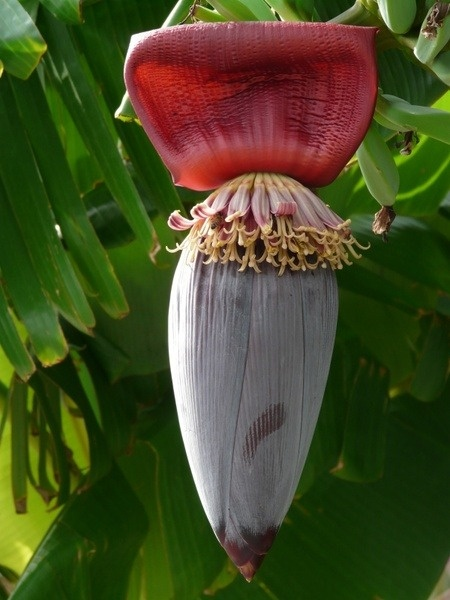

banana_02.jpg


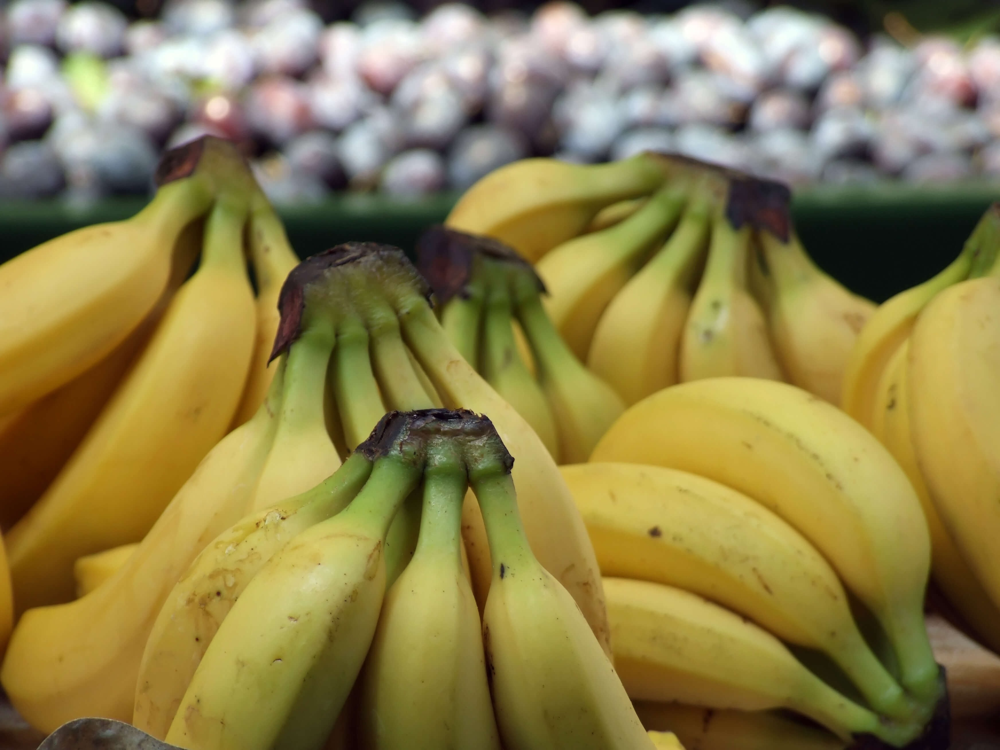

banana_03.jpg


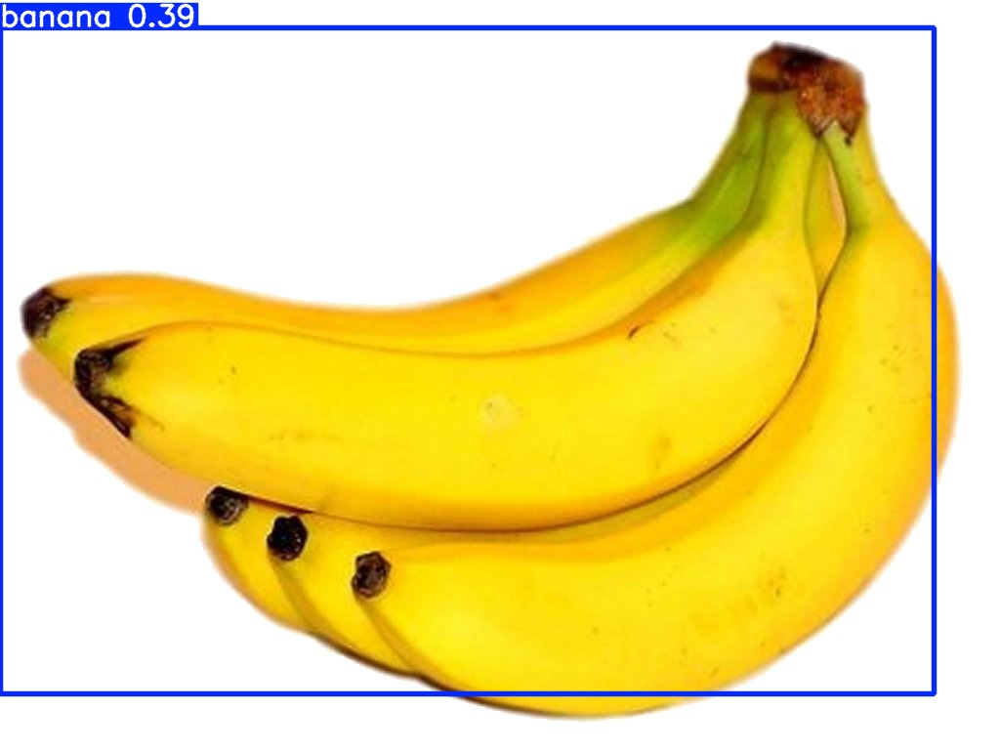

banana_04.jpg


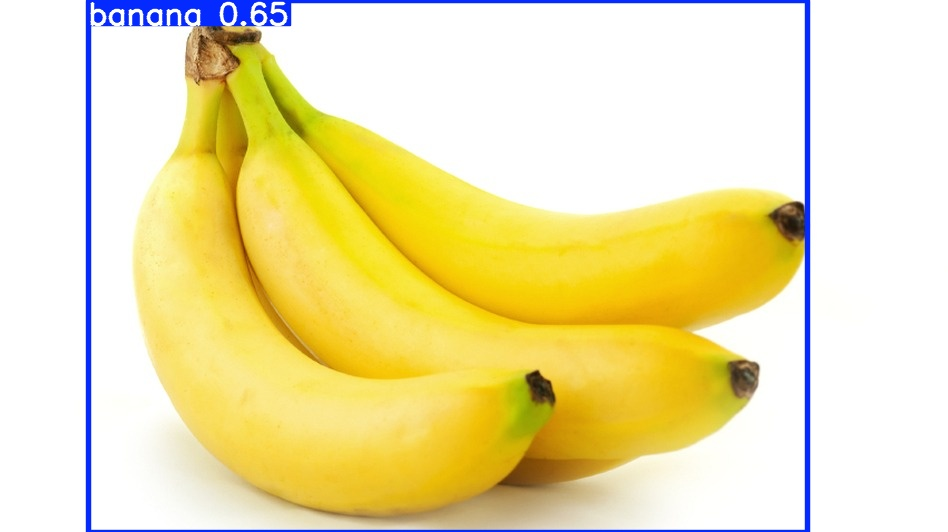

milho_01.jpg


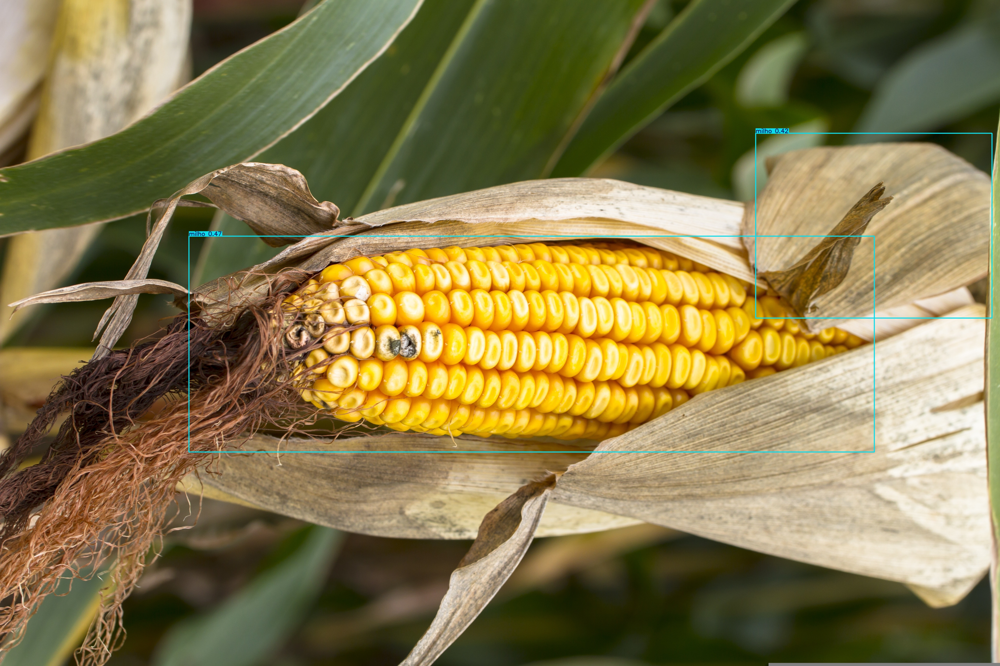

milho_02.jpg


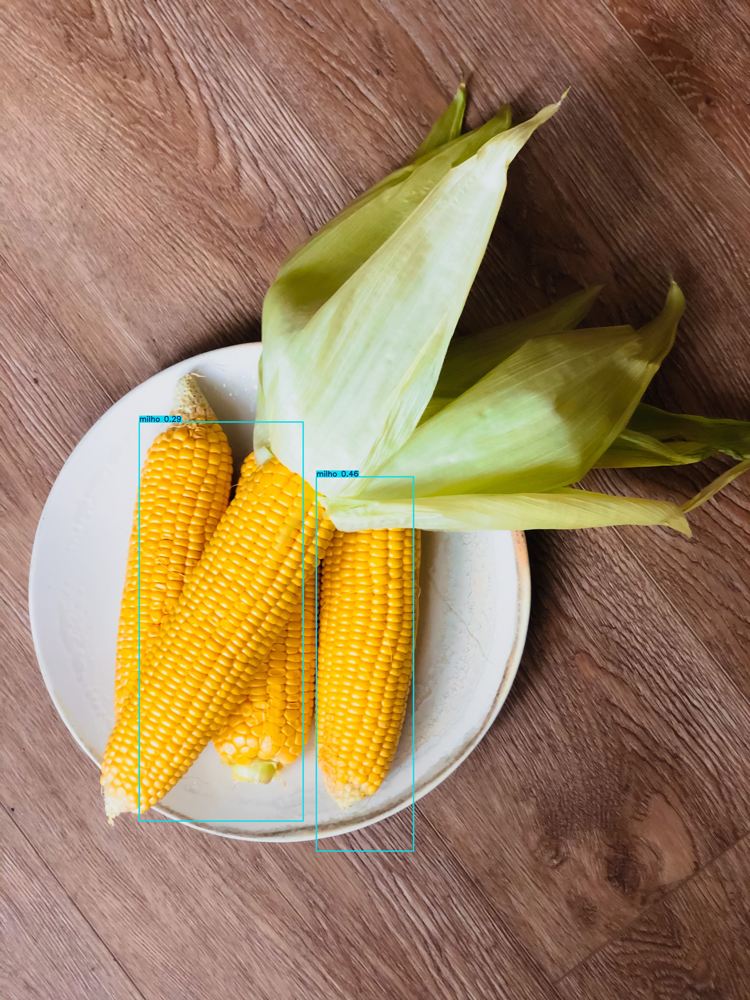

milho_03.jpg


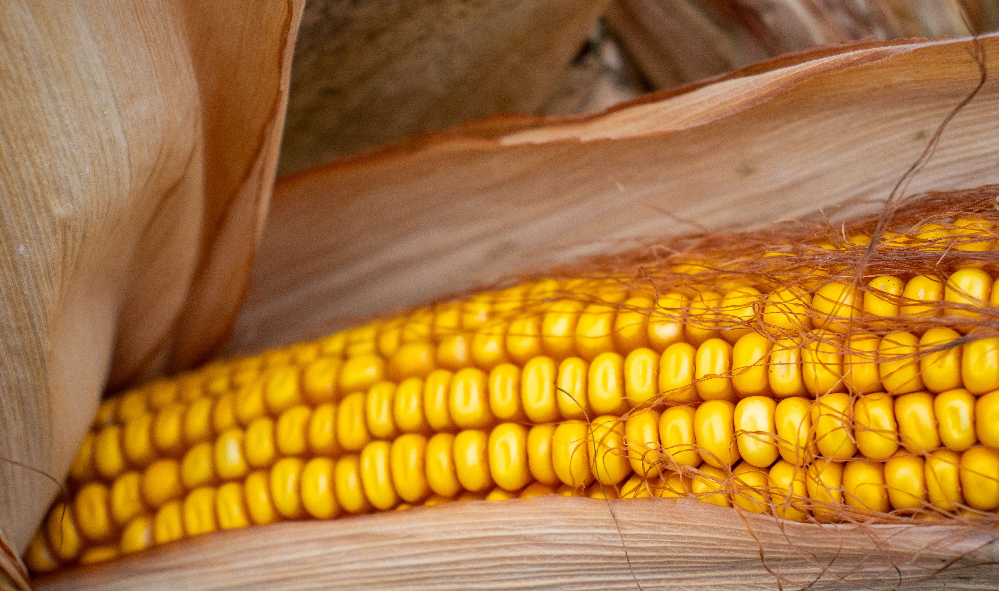

milho_04.jpg


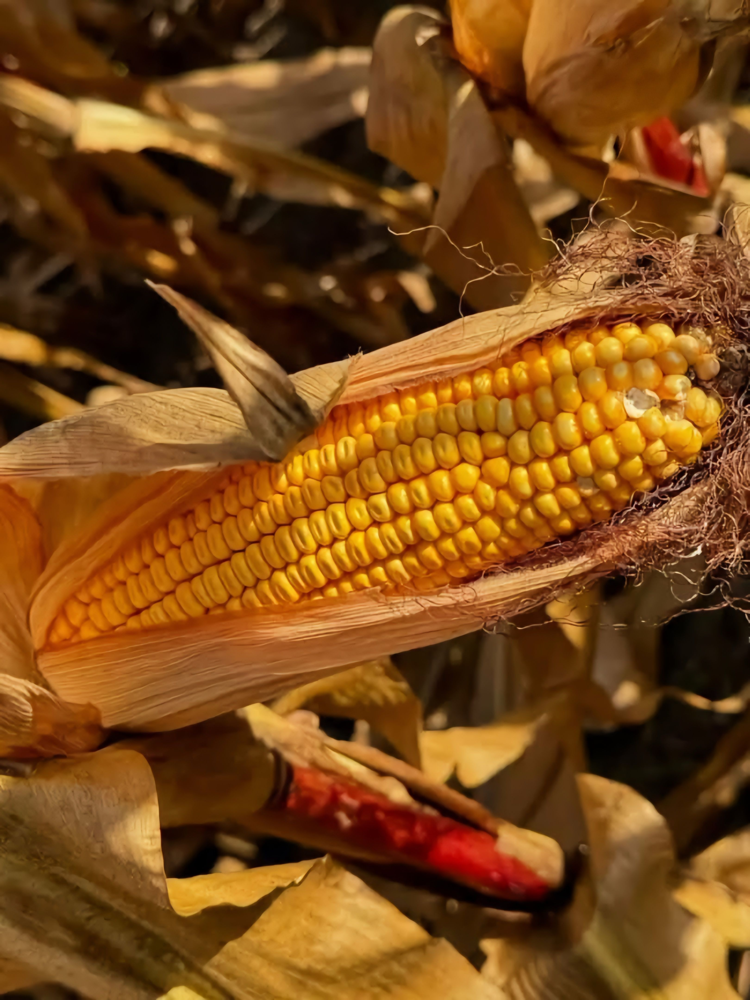

Experimento de 60 épocas
banana_01.jpg


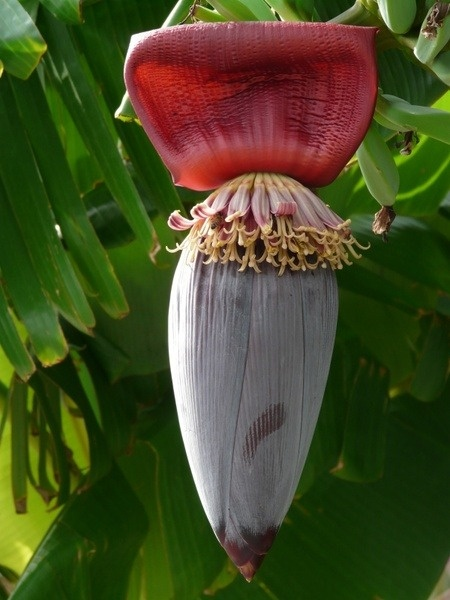

banana_02.jpg


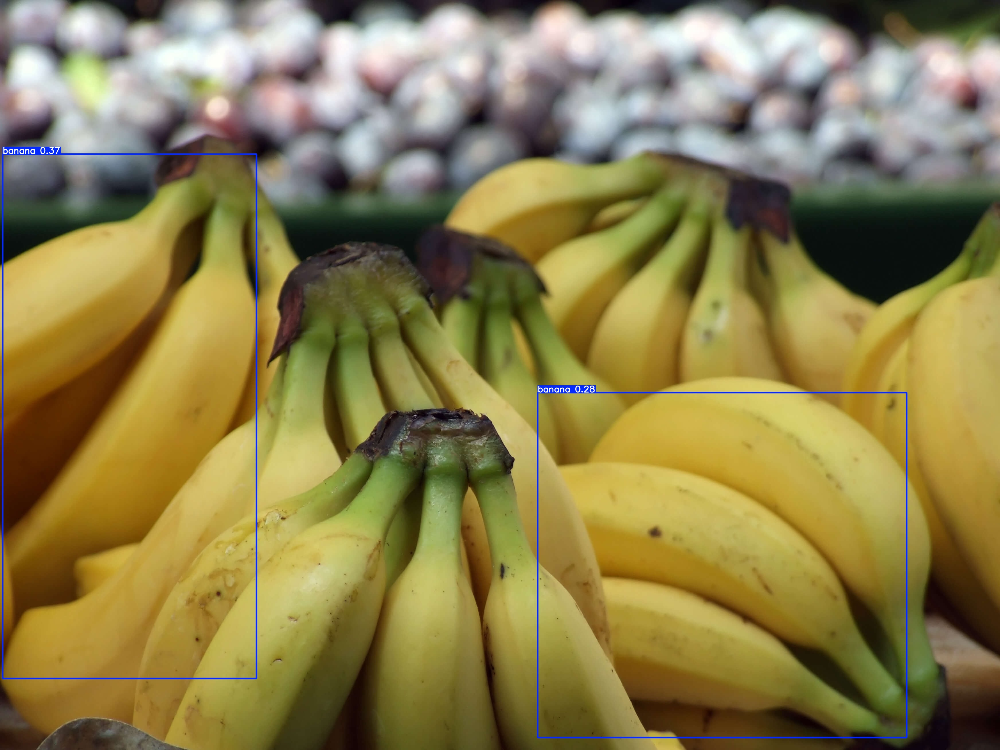

banana_03.jpg


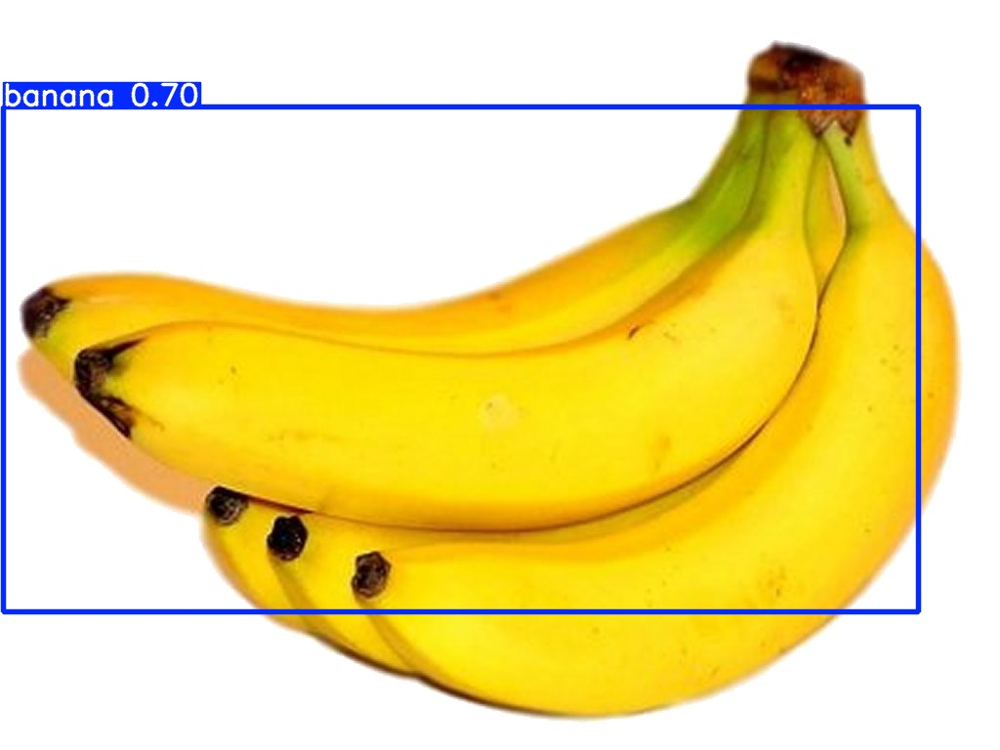

banana_04.jpg


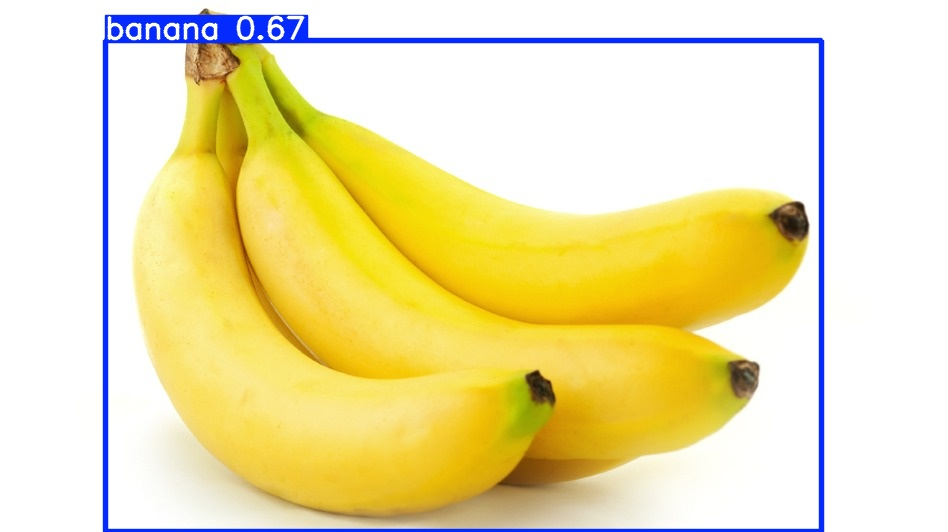

milho_01.jpg


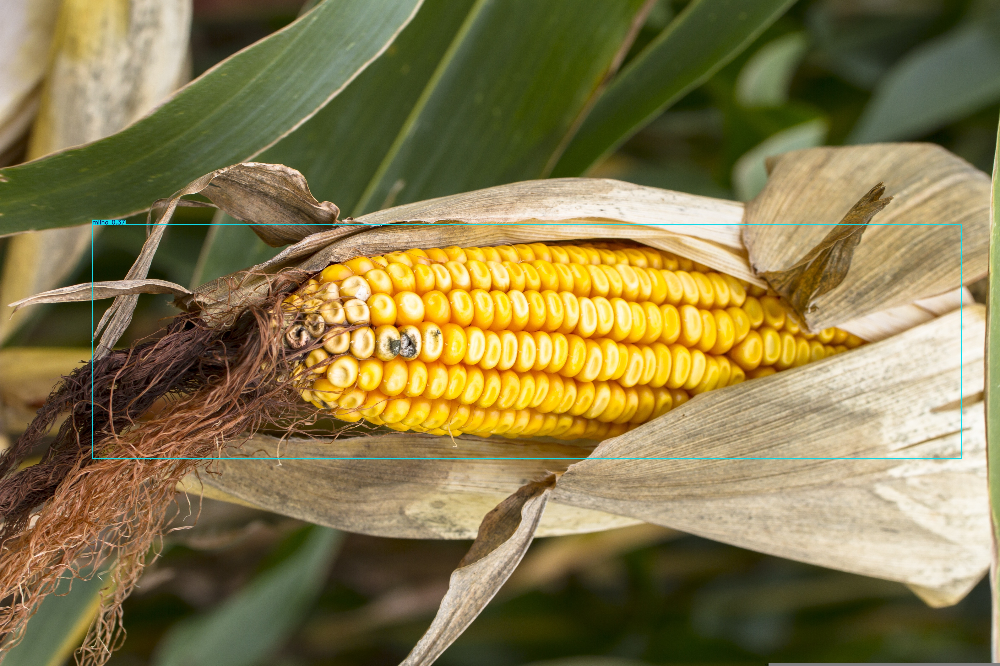

milho_02.jpg


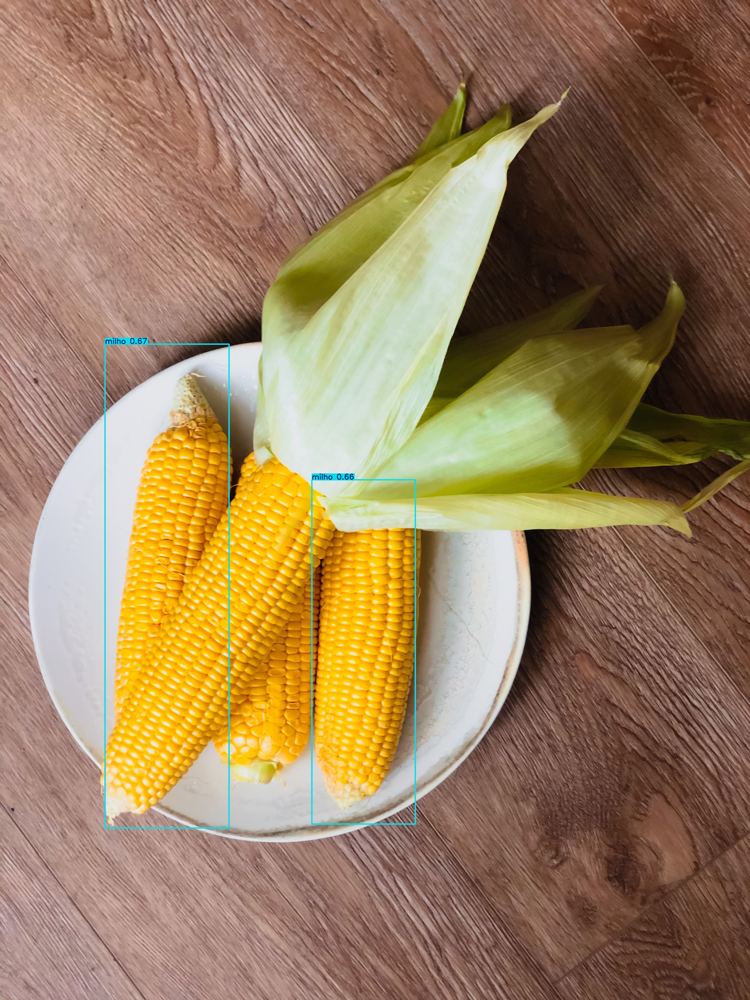

milho_03.jpg


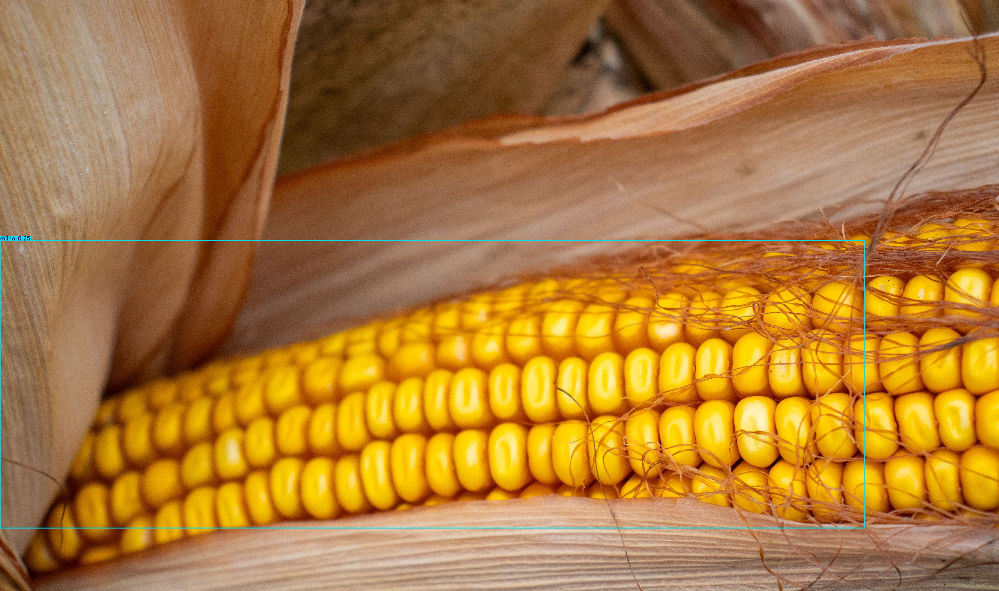

milho_04.jpg


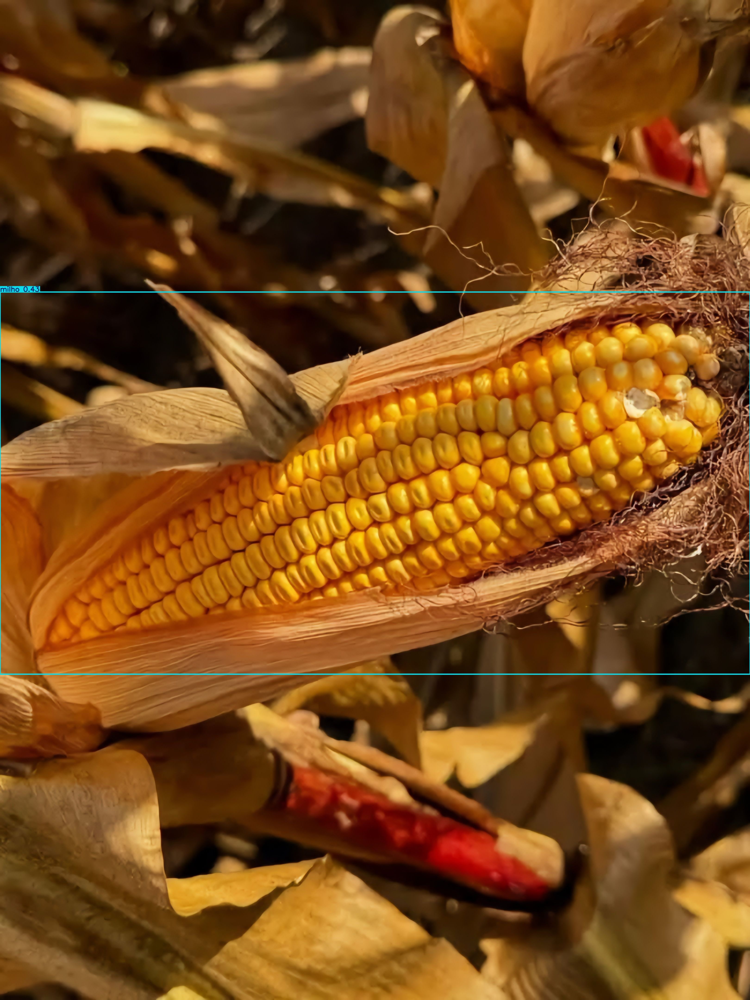

In [ ]:
from pathlib import Path
from IPython.display import Image, display

for nome in ('exp30', 'exp60'):
    pasta = Path('/content/yolov5/runs/detect') / nome
    print('Experimento de 30 épocas' if nome == 'exp30' else 'Experimento de 60 épocas')
    fotos = sorted(pasta.rglob('*.jpg'))
    if not fotos:
        print('Nenhuma foto nesta pasta. Rode a célula de teste antes.')
    for foto in fotos:
        print(foto.name)
        display(Image(filename=str(foto), width=420))

## 12. Comparação

### Métricas globais e tempo

Os valores da linha `all` correspondem à validação do `best.pt` de cada simulação.

| épocas | Precision | Recall | mAP50 | mAP50-95 | Tempo |
| --- | --- | --- | --- | --- | --- |
| 30 | 0.535 | 0.407 | 0.466 | 0.220 | 796 segundos (aproximadamente 13 min 16 s) |
| 60 | 0.811 | 0.511 | 0.567 | 0.319 | 1404 segundos (aproximadamente 23 min 24 s) |

Nesta execução, 60 épocas apresentou melhor desempenho global em todas as métricas principais: Precision de 0.535 para 0.811, Recall de 0.407 para 0.511, mAP50 de 0.466 para 0.567 e mAP50-95 de 0.220 para 0.319. O tempo de treinamento aumentou de 796 s para 1404 s, aproximadamente 76% a mais.

### Losses da última época

| Loss | 30 épocas | 60 épocas |
| --- | --- | --- |
| train/box_loss | 0.05306 | 0.03678 |
| train/obj_loss | 0.04111 | 0.03084 |
| train/cls_loss | 0.008753 | 0.003109 |

As três losses de treinamento listadas terminaram menores na execução de 60 épocas. Elas correspondem à **última época** de cada treinamento, enquanto Precision, Recall e mAP apresentados anteriormente correspondem às **métricas de validação do best.pt**. São referências diferentes e não devem ser confundidas. Losses finais menores complementam a análise, mas não constituem prova isolada de melhor generalização nem significam melhora em todas as classes.

### Comparação por classe

| Classe | épocas | Precision | Recall | mAP50 | mAP50-95 |
| --- | --- | --- | --- | --- | --- |
| banana | 30 | 0.763 | 0.385 | 0.489 | 0.178 |
| banana | 60 | 0.652 | 0.308 | 0.377 | 0.160 |
| milho | 30 | 0.307 | 0.429 | 0.442 | 0.263 |
| milho | 60 | 0.970 | 0.714 | 0.757 | 0.477 |

O comportamento por classe não foi uniforme. Para banana, 30 épocas apresentou métricas superiores às de 60 épocas em todos os indicadores: Precision (0.763 contra 0.652), Recall (0.385 contra 0.308), mAP50 (0.489 contra 0.377) e mAP50-95 (0.178 contra 0.160). Para milho, 60 épocas apresentou melhora em todos os indicadores: Precision de 0.307 para 0.970, Recall de 0.429 para 0.714, mAP50 de 0.442 para 0.757 e mAP50-95 de 0.263 para 0.477.

Nesta execução, o treinamento de 60 épocas apresentou melhor desempenho global, impulsionado principalmente pela melhora expressiva da classe milho. A classe banana, entretanto, apresentou métricas inferiores às obtidas com 30 épocas.

As classes têm o mesmo número de imagens: 32 de treino, 4 de validação e 4 de teste por classe. Entretanto, o treino contém 43 bounding boxes de banana e 101 de milho. O dataset está balanceado em quantidade de imagens, mas não em instâncias anotadas.

As 40 imagens de milho foram escolhidas manualmente, uma a uma, considerando qualidade visual, posição e ângulo das espigas, iluminação, ambiente, presença ou ausência de palha, diversidade de enquadramentos, quantidade de espigas e distância do objeto. A banana foi obtida de uma pasta de um dataset previamente disponível, sem o mesmo processo de seleção manual imagem por imagem. Ambas as classes utilizaram MakeSense.ai, Object Detection e formato YOLO. Na auditoria posterior das bounding boxes, foram observadas maior heterogeneidade e inconsistências nas anotações de banana.

A maior quantidade de instâncias de milho, sua curadoria manual mais criteriosa e as inconsistências observadas posteriormente nas anotações de banana podem estar associadas à melhora expressiva do milho e às diferenças de desempenho entre as classes. Constituem hipóteses plausíveis, mas os dados atuais não permitem estabelecer relação causal.

### Avaliação qualitativa do teste

Os resultados do `detect.py` foram:

| Imagem | Detecções — 30 épocas | Detecções — 60 épocas |
| --- | --- | --- |
| banana_01 | Sem detecção | Sem detecção |
| banana_02 | Sem detecção | Alguma detecção |
| banana_03 | Alguma detecção | Alguma detecção |
| banana_04 | Alguma detecção | Alguma detecção |
| milho_01 | Alguma detecção | Alguma detecção |
| milho_02 | Alguma detecção | Alguma detecção |
| milho_03 | Sem detecção | Alguma detecção |
| milho_04 | Sem detecção | Alguma detecção |

Em 30 épocas, houve pelo menos uma detecção em 4 das 8 imagens; banana_01, banana_02, milho_03 e milho_04 não tiveram detecção. Em 60 épocas, houve pelo menos uma detecção em 7 das 8 imagens; banana_01 continuou sem detecção, enquanto milho_03 passou a apresentar detecção.

Essas contagens são apenas observações qualitativas da cobertura das imagens testadas, não uma medida de acurácia, Precision, Recall ou mAP. Cada imagem pode conter múltiplas instâncias; a avaliação correta também envolve localização, falsos positivos, falsos negativos e qualidade das bounding boxes. Mais caixas não significam necessariamente melhor resultado, pois a quantidade real de objetos pode variar e pode haver falsos positivos. A cobertura qualitativa das imagens de teste foi mais ampla em 60 épocas: houve alguma detecção em 7 das 8 imagens, contra 4 das 8 no experimento de 30 épocas. Essa contagem não substitui Precision, Recall ou mAP, e as contagens isoladas não comprovam a correção das detecções.


## 13. Conclusão

O número de épocas foi a principal variável experimental planejada entre as duas simulações. O treinamento de redes neurais possui componentes estocásticos; portanto, diferenças entre execuções não devem ser atribuídas de forma absoluta apenas ao número de épocas.

Nesta execução, o `best.pt` da simulação de **60 épocas** foi selecionado como modelo final pelas métricas globais de validação. Apresentou Precision maior (0.811 contra 0.535), Recall maior (0.511 contra 0.407), mAP50 maior (0.567 contra 0.466) e mAP50-95 maior (0.319 contra 0.220). As três losses de treinamento do último epoch foram menores, como evidência complementar distinta das métricas de validação do checkpoint selecionado; essa redução não constitui prova isolada de melhor generalização. A cobertura qualitativa das imagens de teste foi mais ampla em 60 épocas: houve alguma detecção em 7 das 8 imagens, contra 4 das 8 no experimento de 30 épocas. Essa cobertura qualitativa não representa acurácia, não substitui Precision, Recall ou mAP nem comprova, isoladamente, a correção das detecções.

Nesta execução, o treinamento de 60 épocas apresentou melhor desempenho global, impulsionado principalmente pela melhora expressiva da classe milho. A classe banana, entretanto, apresentou métricas inferiores às obtidas com 30 épocas. O custo de treinamento passou de 796 para 1404 segundos (aproximadamente 76% mais tempo), e banana_01 continuou sem detecção. Assim, a melhora global não foi uniforme entre as classes. O modelo final é o `best.pt` de `exp60`, persistido em `Meu Drive/FarmTech_Neural_Vision/runs/train`.

Nesta execução, para banana, 30 épocas apresentou valores superiores de Precision, Recall, mAP50 e mAP50-95; para milho, 60 épocas apresentou valores superiores nas quatro métricas. Na comparação entre classes, milho apresentou Recall e mAP50-95 superiores aos de banana nas duas simulações; Precision e mAP50 de milho foram inferiores aos de banana em 30 épocas e superiores em 60 épocas. O milho teve curadoria manual criteriosa e possui 101 instâncias de treino, contra 43 de banana. A banana foi obtida de um dataset previamente disponível, sem a mesma seleção manual, e foram observadas maior heterogeneidade e inconsistências em suas anotações na auditoria posterior. A ferramenta e o formato de rotulagem foram os mesmos para ambas as classes: MakeSense.ai, Object Detection e YOLO. Esses fatores podem estar associados às diferenças de desempenho observadas e constituem hipóteses plausíveis, mas os dados atuais não permitem estabelecer relação causal.

### Pontos fortes

- Divisão explícita em treino, validação e teste, com duas classes visualmente distintas.
- Uso de transfer learning com YOLOv5 pré-treinado e duas simulações com diferentes quantidades de épocas.
- Comparação quantitativa de métricas e avaliação qualitativa das imagens de teste.
- Persistência dos resultados no Google Drive.

### Limitações e melhorias futuras

O dataset é pequeno e restrito a duas classes, com somente 32 imagens de treino, 4 de validação e 4 de teste por classe. O número reduzido de instâncias de validação torna as métricas sensíveis a poucas detecções corretas ou incorretas. Somam-se a isso a heterogeneidade das imagens, os processos diferentes de curadoria, as inconsistências conhecidas nas anotações de banana e a diferença na quantidade de instâncias anotadas entre banana e milho. O resultado por classe não foi uniforme, apesar da melhora global em 60 épocas nesta execução. Essas limitações restringem a estabilidade das conclusões e a generalização dos resultados; um dataset maior e mais homogêneo é necessário para conclusões mais robustas.

Como melhoria futura, propõe-se aplicar à classe banana o mesmo processo de curadoria manual utilizado no milho, revisar e padronizar o critério das bounding boxes, ampliar o dataset de ambas as classes, incluindo as instâncias de banana e os conjuntos de validação e teste, e repetir o treinamento mantendo arquitetura, hiperparâmetros e número de épocas controlados. O objetivo desse novo experimento seria verificar se Precision, Recall, mAP50 e mAP50-95 da classe banana apresentam melhora, sem assumir previamente que isso ocorrerá.
